<a href="https://colab.research.google.com/github/PavelShershov/Machine_Learning/blob/main/PCA_Shershov.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Понизить размерность набора данных MNIST с помощью PCA (`n_components = 0.80, 0.90 или 0.95`).

2. К преобразованному набору данных применить t-SNE (`n_components = 2 и 3`).

3. Визуализировать полученные результаты.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


In [ ]:
print('Загрузка MNIST...')
start_time = time.time()

mnist = fetch_openml(
    name='mnist_784',
    version=1,
    as_frame=False
)

X = mnist.data.astype(np.float32) / 255.0
y = mnist.target.astype(int)

print('Загрузка завершена за', round(time.time() - start_time, 1), 'сек.')
print('Размер набора данных:', X.shape)


Загрузка MNIST...
Загрузка завершена за 109.4 сек.
Размер набора данных: (70000, 784)


In [ ]:
print('Начато уменьшение размерности с помощью PCA...')
start_time = time.time()

pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X)

print('PCA завершён за', round(time.time() - start_time, 1), 'сек.')
print('Исходное количество признаков:', X.shape[1])
print('Количество компонент после PCA:', X_pca.shape[1])
print('Сохранённая дисперсия:', round(pca.explained_variance_ratio_.sum() * 100, 2), '%')
print('Размер данных после PCA:', X_pca.shape)


Начато уменьшение размерности с помощью PCA...
PCA завершён за 1.5 сек.
Исходное количество признаков: 784
Количество компонент после PCA: 154
Сохранённая дисперсия: 95.04 %
Размер данных после PCA: (70000, 154)


In [ ]:
print('Начато построение t-SNE в 2D...')
start_time = time.time()

tsne_2d = TSNE(
    n_components=2,
    verbose=2
)
X_tsne_2d = tsne_2d.fit_transform(X_pca)

print('t-SNE 2D завершён за', round(time.time() - start_time, 1), 'сек.')
print('Размерность результата t-SNE 2D:', X_tsne_2d.shape)


Начато построение t-SNE в 2D...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 70000 samples in 0.008s...
[t-SNE] Computed neighbors for 70000 samples in 87.632s...
[t-SNE] Computed conditional probabilities for sample 1000 / 70000
[t-SNE] Computed conditional probabilities for sample 2000 / 70000
[t-SNE] Computed conditional probabilities for sample 3000 / 70000
[t-SNE] Computed conditional probabilities for sample 4000 / 70000
[t-SNE] Computed conditional probabilities for sample 5000 / 70000
[t-SNE] Computed conditional probabilities for sample 6000 / 70000
[t-SNE] Computed conditional probabilities for sample 7000 / 70000
[t-SNE] Computed conditional probabilities for sample 8000 / 70000
[t-SNE] Computed conditional probabilities for sample 9000 / 70000
[t-SNE] Computed conditional probabilities for sample 10000 / 70000
[t-SNE] Computed conditional probabilities for sample 11000 / 70000
[t-SNE] Computed conditional probabilities for sample 12000 / 70000
[t-SNE] Computed 

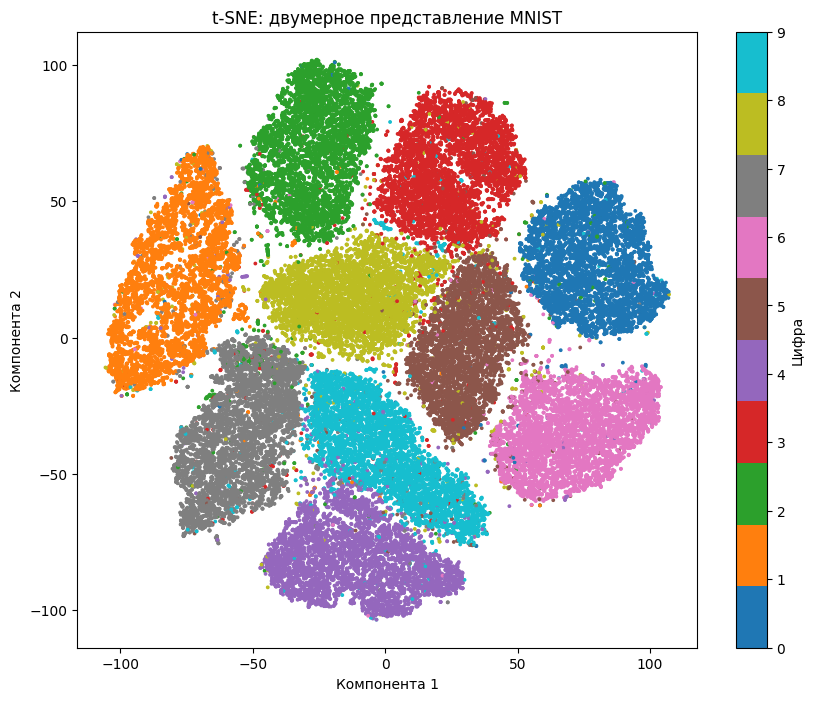

In [ ]:
plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    X_tsne_2d[:, 0],
    X_tsne_2d[:, 1],
    c=y,
    cmap='tab10',
    s=3
)

plt.colorbar(scatter, ticks=range(10), label='Цифра')
plt.title('t-SNE: двумерное представление MNIST')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.show()


In [ ]:
print('Начато построение t-SNE в 3D...')
start_time = time.time()

tsne_3d = TSNE(
    n_components=3,
    verbose=2
)
X_tsne_3d = tsne_3d.fit_transform(X_pca)

print('t-SNE 3D завершён за', round(time.time() - start_time, 1), 'сек.')
print('Размерность результата t-SNE 3D:', X_tsne_3d.shape)


Начато построение t-SNE в 3D...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 70000 samples in 0.011s...
[t-SNE] Computed neighbors for 70000 samples in 86.079s...
[t-SNE] Computed conditional probabilities for sample 1000 / 70000
[t-SNE] Computed conditional probabilities for sample 2000 / 70000
[t-SNE] Computed conditional probabilities for sample 3000 / 70000
[t-SNE] Computed conditional probabilities for sample 4000 / 70000
[t-SNE] Computed conditional probabilities for sample 5000 / 70000
[t-SNE] Computed conditional probabilities for sample 6000 / 70000
[t-SNE] Computed conditional probabilities for sample 7000 / 70000
[t-SNE] Computed conditional probabilities for sample 8000 / 70000
[t-SNE] Computed conditional probabilities for sample 9000 / 70000
[t-SNE] Computed conditional probabilities for sample 10000 / 70000
[t-SNE] Computed conditional probabilities for sample 11000 / 70000
[t-SNE] Computed conditional probabilities for sample 12000 / 70000
[t-SNE] Computed 

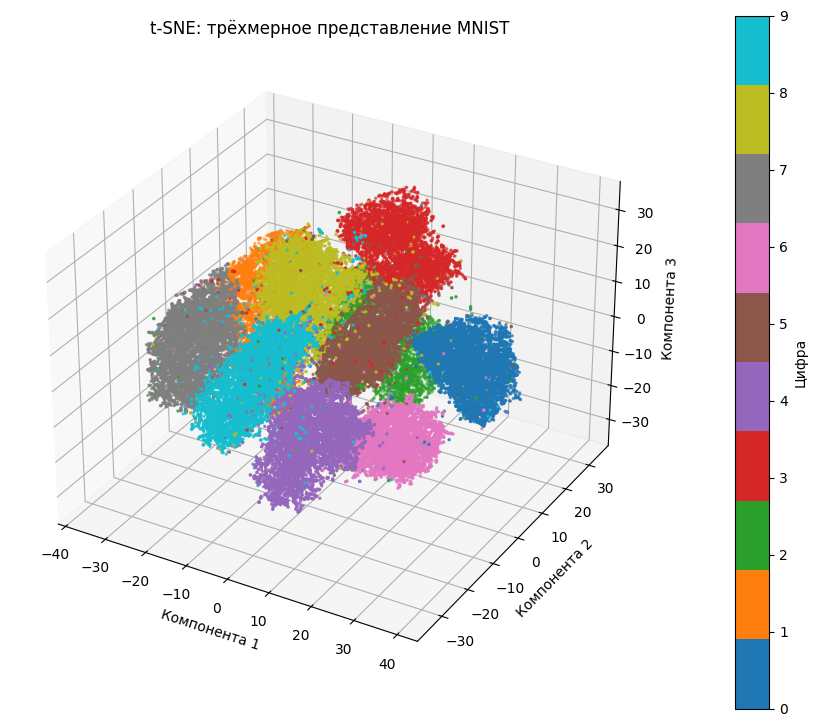

In [ ]:
fig = plt.figure(figsize=(11, 9))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    X_tsne_3d[:, 0],
    X_tsne_3d[:, 1],
    X_tsne_3d[:, 2],
    c=y,
    cmap='tab10',
    s=2
)

fig.colorbar(scatter, ax=ax, ticks=range(10), label='Цифра', pad=0.1)
ax.set_title('t-SNE: трёхмерное представление MNIST')
ax.set_xlabel('Компонента 1')
ax.set_ylabel('Компонента 2')
ax.set_zlabel('Компонента 3')
plt.show()


In [ ]:
print('ИТОГОВЫЕ РЕЗУЛЬТАТЫ')
print('Количество изображений:', X.shape[0])
print('Исходное количество признаков:', X.shape[1])
print('Количество компонент после PCA:', X_pca.shape[1])
print('Сохранённая дисперсия:', round(pca.explained_variance_ratio_.sum() * 100, 2), '%')
print('Количество координат t-SNE 2D:', X_tsne_2d.shape[1])
print('Количество координат t-SNE 3D:', X_tsne_3d.shape[1])


ИТОГОВЫЕ РЕЗУЛЬТАТЫ
Количество изображений: 70000
Исходное количество признаков: 784
Количество компонент после PCA: 154
Сохранённая дисперсия: 95.04 %
Количество координат t-SNE 2D: 2
Количество координат t-SNE 3D: 3
